**Introducción a la Ciencia de Datos 2026**  
Posgrado en Ciencias de la Computación - CICESE  
M.C. Joan Manuel Raygoza Romero

# ICD - 21: Redes neuronales convolucionales

Sesión 21 del curso. Diapositivas: [icd-21-cnn.pdf](https://github.com/husseinlopez/icd2026/blob/main/clases/icd-21-cnn.pdf)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/husseinlopez/icd2026/blob/main/icd-21-cnn.ipynb)

Entrenaremos una CNN pequeña en **TensorFlow/Keras** para reconocer dígitos manuscritos de MNIST. Mantendremos fijos los datos y el entrenamiento al modificar la arquitectura. Después veremos qué ocurre si cambiamos la posición de un dígito en la imagen.

Ejecuta las celdas en orden en Jupyter o Colab. Puedes trabajar en CPU. MNIST se descarga en la primera ejecución. Si falta alguna dependencia en Jupyter, ejecuta en una celda y reinicia el kernel.

```python
%pip install tensorflow numpy pandas matplotlib scikit-learn
```

## 1. Preparar y visualizar los datos

MNIST contiene imágenes de **28 × 28** en escala de grises y diez clases, del 0 al 9. Usamos subconjuntos estratificados para que la práctica sea corta. Conservamos la separación oficial de prueba y tomamos la validación del conjunto oficial de entrenamiento.

Añadimos cuatro píxeles de margen negro a cada lado en las tres particiones. Así, más adelante podremos desplazar un dígito hasta cuatro píxeles sin recortar la imagen original. La forma que recibe la red es **36 × 36 × 1**.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Entrenamiento: (8000, 36, 36, 1)
Validación: (1500, 36, 36, 1)
Prueba: (2000, 36, 36, 1)


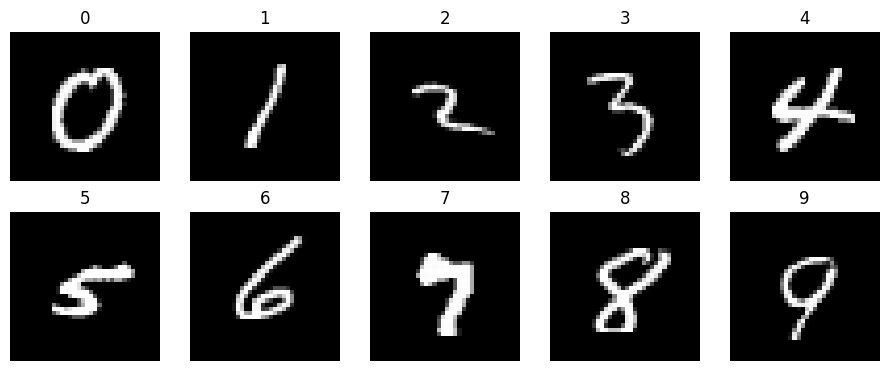

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from tensorflow import keras

SEMILLA = 42
N_ENT, N_VAL, N_PRUEBA = 8000, 1500, 2000
MARGEN = 4

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

(x_des, y_des), (x_test, y_test) = keras.datasets.mnist.load_data()
i_ent, i_val = train_test_split(
    np.arange(len(y_des)), train_size=N_ENT, test_size=N_VAL,
    stratify=y_des, random_state=SEMILLA,
)
i_prueba, _ = train_test_split(
    np.arange(len(y_test)), train_size=N_PRUEBA, stratify=y_test,
    random_state=SEMILLA,
)

def preparar_imagenes(imagenes):
    imagenes = np.pad(imagenes, ((0, 0), (MARGEN, MARGEN), (MARGEN, MARGEN)))
    return imagenes[..., None].astype(np.float32) / 255.0

X_ent, y_ent = preparar_imagenes(x_des[i_ent]), y_des[i_ent]
X_val, y_val = preparar_imagenes(x_des[i_val]), y_des[i_val]
X_prueba, y_prueba = preparar_imagenes(x_test[i_prueba]), y_test[i_prueba]
FORMA = X_ent.shape[1:]
for nombre, X in [("Entrenamiento", X_ent), ("Validación", X_val), ("Prueba", X_prueba)]:
    print(f"{nombre}: {X.shape}")

fig, ejes = plt.subplots(2, 5, figsize=(9, 3.6), layout="constrained")
for digito, ax in enumerate(ejes.flat):
    i = np.flatnonzero(y_ent == digito)[0]
    ax.imshow(X_ent[i, ..., 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(str(digito))
    ax.axis("off")
plt.show()

## 2. Entrenar una MLP y una CNN pequeña

La **MLP** aplana la imagen y conecta sus píxeles a una capa densa de 40 neuronas. La **CNN** aplica dos convoluciones de 16 filtros de 3 × 3 con ReLU, un *max pooling* de 2 × 2 y una salida densa de diez clases. Ambas usan el mismo lote, optimizador, tasa y número de épocas. Sus tamaños son parecidos, como puedes comprobar con `count_params()`.

En la CNN dejamos el pooling después de la última convolución. Esto permitirá agregar o quitar convoluciones sin cambiar el número de operaciones de pooling. **Antes de ejecutar**, predice el tamaño de salida del pooling con una entrada de 36 × 36 y `padding="same"`.

In [20]:
CAPAS = (16, 16)
LOTE = 128
EPOCAS = 20
TASA = 0.001

def crear_cnn(filtros=CAPAS, padding="same", pooling="max", stride=1, cabeza="flatten"):
    capas = [keras.Input(shape=FORMA)]
    for i, n_filtros in enumerate(filtros):
        capas.append(keras.layers.Conv2D(
            n_filtros, 3, strides=stride if i == 0 else 1,
            padding=padding, activation="relu", name=f"conv_{i + 1}",
        ))
    if pooling == "max":
        capas.append(keras.layers.MaxPooling2D(2, name="pool"))
    elif pooling == "average":
        capas.append(keras.layers.AveragePooling2D(2, name="pool"))
    elif pooling != "sin":
        raise ValueError("pooling debe ser 'max', 'average' o 'sin'")

    if cabeza == "flatten":
        capas.append(keras.layers.Flatten(name="vector"))
    elif cabeza == "gap":
        capas.append(keras.layers.GlobalAveragePooling2D(name="vector"))
    else:
        raise ValueError("cabeza debe ser 'flatten' o 'gap'")

    capas.append(keras.layers.Dense(10, activation="softmax", name="salida"))
    return keras.Sequential(capas, name=f"cnn_{cabeza}")

def crear_mlp():
    return keras.Sequential([
        keras.Input(shape=FORMA),
        keras.layers.Flatten(),
        keras.layers.Dense(40, activation="relu"),
        keras.layers.Dense(10, activation="softmax"),
    ], name="mlp")

def lotes(X, y=None, mezclar=False):
    datos = tf.data.Dataset.from_tensor_slices(X if y is None else (X, y))
    if mezclar:
        datos = datos.shuffle(len(X), seed=SEMILLA)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 2
    return datos.batch(LOTE).with_options(opciones).prefetch(1)

def entrenar(constructor, **configuracion):
    keras.utils.set_random_seed(SEMILLA)
    modelo = constructor(**configuracion)
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=TASA),
        loss="sparse_categorical_crossentropy",
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )
    historial = modelo.fit(
        lotes(X_ent, y_ent, mezclar=True),
        validation_data=lotes(X_val, y_val),
        epochs=EPOCAS, verbose=0, shuffle=False,  # lotes() ya mezcla los datos
    ).history
    return modelo, historial

modelo_mlp, hist_mlp = entrenar(crear_mlp)
modelo_cnn, hist_cnn = entrenar(crear_cnn)
modelo_cnn.summary()
modelo_mlp.summary()

Model: "cnn_flatten"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 36, 36, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 36, 36, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool (MaxPooling2D)             │ (None, 18, 18, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vector (Flatten)                │ (None, 5184)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 10)             │        51,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 162,992 (636.69 KB)

 Trainable params: 54,330 (212.23 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 108,662 (424.46 KB)

... (2 outputs left out)

 Total params: 156,872 (612.79 KB)

 Trainable params: 52,290 (204.26 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 104,582 (408.53 KB)

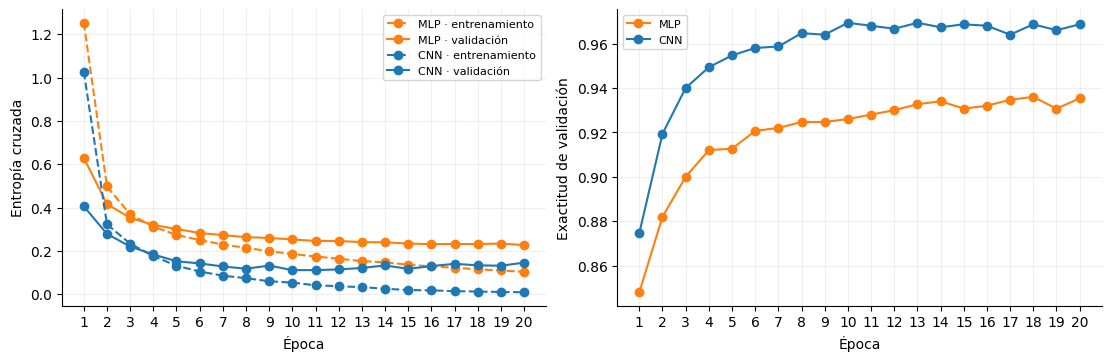

,Modelo,Parámetros entrenables,Exactitud validación (%)
0,MLP,52290,93.53
1,CNN,54330,96.87


In [21]:
def curvas(ax, historial, metrica, etiqueta, color, estilo="-"):
    valores = historial[metrica]
    ax.plot(range(1, len(valores) + 1), valores, estilo, marker="o",
            label=etiqueta, color=color)

def resumen_modelo(nombre, modelo, historial):
    return {
        "Modelo": nombre,
        "Parámetros entrenables": sum(int(np.prod(v.shape)) for v in modelo.trainable_weights),
        "Exactitud validación (%)": 100 * historial["val_accuracy"][-1],
    }

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
for nombre, historial, color in [("MLP", hist_mlp, "C1"), ("CNN", hist_cnn, "C0")]:
    curvas(ejes[0], historial, "loss", f"{nombre} · entrenamiento", color, "--")
    curvas(ejes[0], historial, "val_loss", f"{nombre} · validación", color)
    curvas(ejes[1], historial, "val_accuracy", nombre, color)

for ax, ylabel in zip(ejes, ["Entropía cruzada", "Exactitud de validación"]):
    ax.set(xlabel="Época", ylabel=ylabel, xticks=range(1, EPOCAS + 1))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.show()

display(pd.DataFrame([
    resumen_modelo("MLP", modelo_mlp, hist_mlp),
    resumen_modelo("CNN", modelo_cnn, hist_cnn),
]).round(2))

## 3. Ver los filtros y sus mapas de activación

En la primera capa cada filtro es una matriz de **3 × 3** porque la imagen tiene un canal. El mapa de activación muestra cuánto respondió ese filtro, después de ReLU, en distintas posiciones de **una imagen concreta**.

Cada columna muestra un filtro de la primera capa y el mapa que le corresponde. En la segunda capa, cada filtro recibe los **16 canales** de la anterior. Para esa capa miraremos los mapas resultantes.

**Para observar.** ¿En qué parte del dígito responde más cada filtro? ¿Qué mapas se activan sobre trazos y cuáles cerca del contorno?

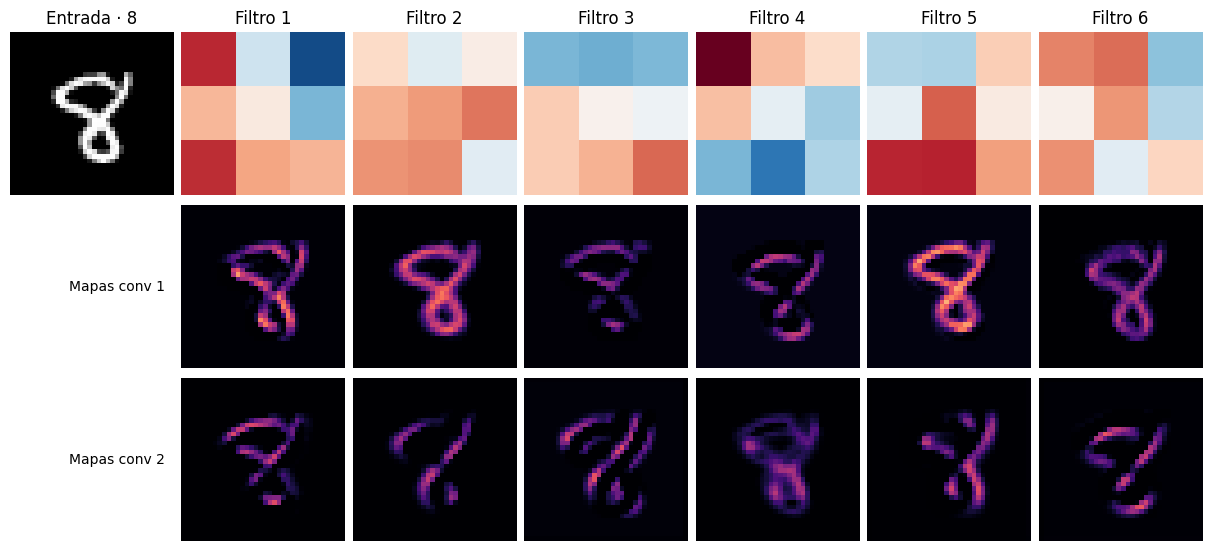

In [22]:
DIGITO = 8
i = np.flatnonzero(y_val == DIGITO)[0]
imagen = X_val[i:i + 1]
convoluciones = [capa for capa in modelo_cnn.layers if isinstance(capa, keras.layers.Conv2D)]
extractor = keras.Model(inputs=modelo_cnn.inputs[0], outputs=[capa.output for capa in convoluciones])
mapas_1, mapas_2 = [mapa.numpy()[0] for mapa in extractor(imagen, training=False)]
pesos, _ = convoluciones[0].get_weights()
lim_peso = float(np.abs(pesos).max())

fig, ejes = plt.subplots(3, 7, figsize=(12, 5.4), layout="constrained")
for ax in ejes.flat:
    ax.axis("off")
ejes[0, 0].imshow(imagen[0, ..., 0], cmap="gray", vmin=0, vmax=1)
ejes[0, 0].set_title(f"Entrada · {DIGITO}")
ejes[1, 0].text(0.95, 0.5, "Mapas conv 1", ha="right", va="center",
                transform=ejes[1, 0].transAxes)
ejes[2, 0].text(0.95, 0.5, "Mapas conv 2", ha="right", va="center",
                transform=ejes[2, 0].transAxes)

for f in range(6):
    ejes[0, f + 1].imshow(pesos[:, :, 0, f], cmap="RdBu_r",
                          vmin=-lim_peso, vmax=lim_peso, interpolation="nearest")
    ejes[0, f + 1].set_title(f"Filtro {f + 1}")
    ejes[1, f + 1].imshow(mapas_1[..., f], cmap="magma", vmin=0, vmax=mapas_1.max() or 1)
    ejes[2, f + 1].imshow(mapas_2[..., f], cmap="magma", vmin=0, vmax=mapas_2.max() or 1)
plt.show()

## 4. Experimentos de arquitectura

La CNN de referencia usa **2 convoluciones, 16 filtros por capa, padding same, stride 1 y max pooling**. Cada panel cambia una sola decisión de diseño. Observa la última forma espacial, la cantidad de parámetros y la exactitud de validación.

- **Profundidad y filtros.** Agregamos o quitamos capas, o cambiamos el ancho de las dos capas a la vez.
- **Padding y stride.** Cambiamos el padding de todas las convoluciones o el stride de la primera. Las demás conservan stride 1.
- **Pooling.** Comparamos máximo, promedio y ausencia de pooling. La operación en sí carece de pesos entrenables. Si cambia el tamaño que llega a Flatten, también cambia el número de pesos de la capa densa.

**Antes de ejecutar.** ¿Qué dos variantes de pooling deberían tener exactamente el mismo número de parámetros? ¿Qué pasará con el número de parámetros al quitar pooling?

Entrenando 1. Capas convolucionales · 1 capa
Entrenando 1. Capas convolucionales · 3 capas
Entrenando 2. Filtros por capa · 8 filtros
Entrenando 2. Filtros por capa · 32 filtros
Entrenando 3. Padding · valid
Entrenando 4. Pooling · promedio
Entrenando 4. Pooling · sin pooling
Entrenando 5. Stride inicial · stride 2


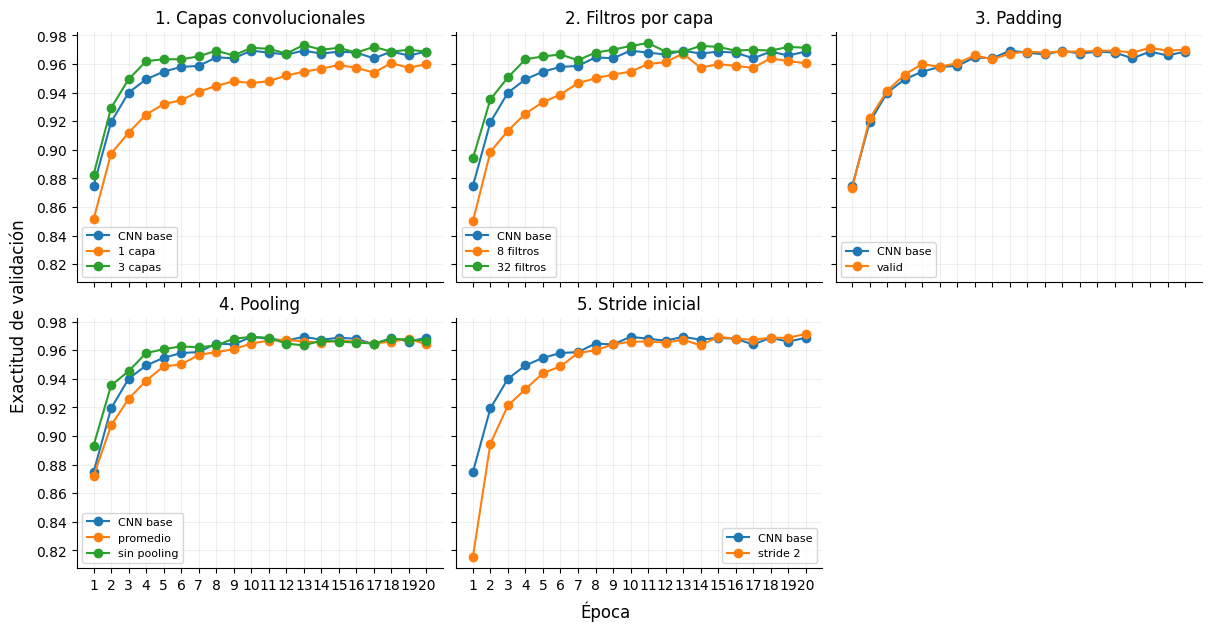

,Experimento,Modelo,Parámetros entrenables,Exactitud validación (%),Mapas antes del vector
0,Referencia,CNN base,54330,96.87,18 × 18 × 16
1,1. Capas convolucionales,1 capa,52010,96.00,18 × 18 × 16
2,1. Capas convolucionales,3 capas,56650,96.87,18 × 18 × 16
3,2. Filtros por capa,8 filtros,26594,96.07,18 × 18 × 8
4,2. Filtros por capa,32 filtros,113258,97.13,18 × 18 × 32
5,3. Padding,valid,43450,97.00,16 × 16 × 16
6,4. Pooling,promedio,54330,96.40,18 × 18 × 16
7,4. Pooling,sin pooling,209850,96.67,36 × 36 × 16
8,5. Stride inicial,stride 2,15450,97.13,9 × 9 × 16


In [23]:
experimentos = {
    "1. Capas convolucionales": [("1 capa", {"filtros": (16,)}),
                               ("3 capas", {"filtros": (16, 16, 16)})],
    "2. Filtros por capa": [("8 filtros", {"filtros": (8, 8)}),
                          ("32 filtros", {"filtros": (32, 32)})],
    "3. Padding": [("valid", {"padding": "valid"})],
    "4. Pooling": [("promedio", {"pooling": "average"}), ("sin pooling", {"pooling": "sin"})],
    "5. Stride inicial": [("stride 2", {"stride": 2})],
}

def resumen_cnn(nombre, modelo, historial):
    resumen = resumen_modelo(nombre, modelo, historial)
    forma = modelo.get_layer("vector").input.shape[1:]
    resumen["Mapas antes del vector"] = " × ".join(str(d) for d in forma)
    return resumen

resultados = [{"Experimento": "Referencia", **resumen_cnn("CNN base", modelo_cnn, hist_cnn)}]
fig, ejes = plt.subplots(2, 3, figsize=(12, 6.2), sharex=True, sharey=True, layout="constrained")

for ax, (grupo, variantes) in zip(ejes.flat, experimentos.items()):
    curvas(ax, hist_cnn, "val_accuracy", "CNN base", "C0")
    for k, (etiqueta, cambio) in enumerate(variantes, start=1):
        print(f"Entrenando {grupo} · {etiqueta}")
        variante, historial = entrenar(crear_cnn, **cambio)
        curvas(ax, historial, "val_accuracy", etiqueta, f"C{k}")
        resultados.append({"Experimento": grupo, **resumen_cnn(etiqueta, variante, historial)})
    ax.set(title=grupo, xticks=range(1, EPOCAS + 1))
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

ejes.flat[-1].axis("off")
fig.supxlabel("Época")
fig.supylabel("Exactitud de validación")
plt.show()
display(pd.DataFrame(resultados).round(2))

## 5. Comparar Flatten y Global Average Pooling

Entrenamos la misma arquitectura convolucional con una cabeza **Global Average Pooling (GAP)**. Los dos modelos tienen la misma configuración del extractor y se entrenan por separado de extremo a extremo. La única decisión de arquitectura que cambia es cómo llegan las activaciones a la capa de diez clases.

Si los mapas tienen forma $H\times W\times C$, Flatten entrega $HWC$ valores y GAP entrega $C$. La capa densa añade un sesgo por clase, así que sus conteos son $(HWC+1)\times10$ y $(C+1)\times10$.

**Antes de ejecutar.** Usa el tamaño de los mapas de la CNN base para calcular ambos conteos de la capa densa.

,Modelo,Parámetros entrenables,Exactitud validación (%),Mapas antes del vector,Longitud del vector,Parámetros capa densa
0,Flatten,54330,96.87,18 × 18 × 16,5184,51850
1,GAP,2650,44.07,18 × 18 × 16,16,170


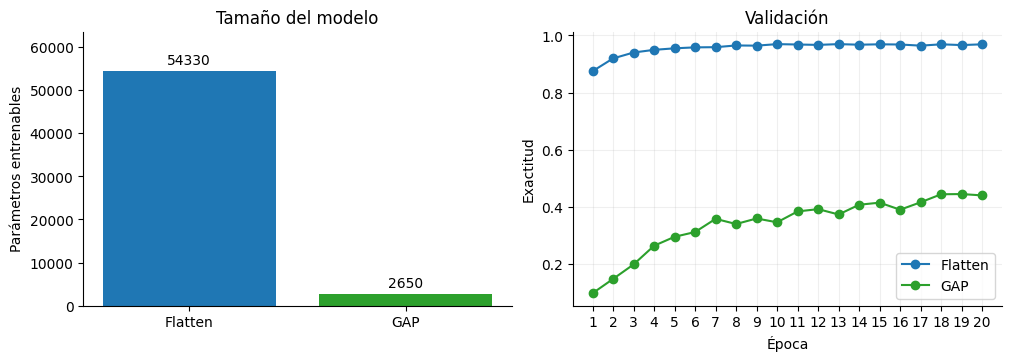

In [24]:
modelo_gap, hist_gap = entrenar(crear_cnn, cabeza="gap")
comparacion = [
    ("Flatten", modelo_cnn, hist_cnn),
    ("GAP", modelo_gap, hist_gap),
]
tabla_cabezas = []
for nombre, modelo, historial in comparacion:
    fila = resumen_cnn(nombre, modelo, historial)
    fila["Longitud del vector"] = int(modelo.get_layer("vector").output.shape[-1])
    fila["Parámetros capa densa"] = modelo.get_layer("salida").count_params()
    tabla_cabezas.append(fila)
tabla_cabezas = pd.DataFrame(tabla_cabezas)
display(tabla_cabezas.round(2))

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
barras = ejes[0].bar(tabla_cabezas["Modelo"], tabla_cabezas["Parámetros entrenables"],
                     color=["C0", "C2"])
ejes[0].bar_label(barras, padding=3)
ejes[0].set(title="Tamaño del modelo", ylabel="Parámetros entrenables")
ejes[0].margins(y=0.17)
for (nombre, _, historial), color in zip(comparacion, ("C0", "C2")):
    curvas(ejes[1], historial, "val_accuracy", nombre, color)
ejes[1].set(title="Validación", xlabel="Época", ylabel="Exactitud",
            xticks=range(1, EPOCAS + 1))
ejes[1].legend()
ejes[1].grid(alpha=0.2)
plt.show()

## 6. Evaluar en prueba y desplazar las imágenes después de entrenar

Evaluamos **MLP, CNN con Flatten y CNN con GAP** sobre los mismos dígitos de prueba. Primero usamos las imágenes centradas en su marco original. Luego desplazamos cada imagen **2 y 4 píxeles** a la izquierda, derecha, arriba y abajo. Los píxeles vacíos quedan en negro. Evaluamos los modelos ya entrenados con los mismos pesos en todas las posiciones.

La curva muestra la exactitud media entre las cuatro direcciones para cada desplazamiento positivo. A 0 píxeles se usa una sola evaluación. La tabla también muestra la caída a 4 píxeles en puntos porcentuales.

,0 px (%),2 px (%),4 px (%),Caída a 4 px (pp)
Modelo,,,,
MLP,94.00,65.21,19.80,74.20
CNN + Flatten,97.15,82.81,37.21,59.94
CNN + GAP,46.35,46.36,46.38,-0.02


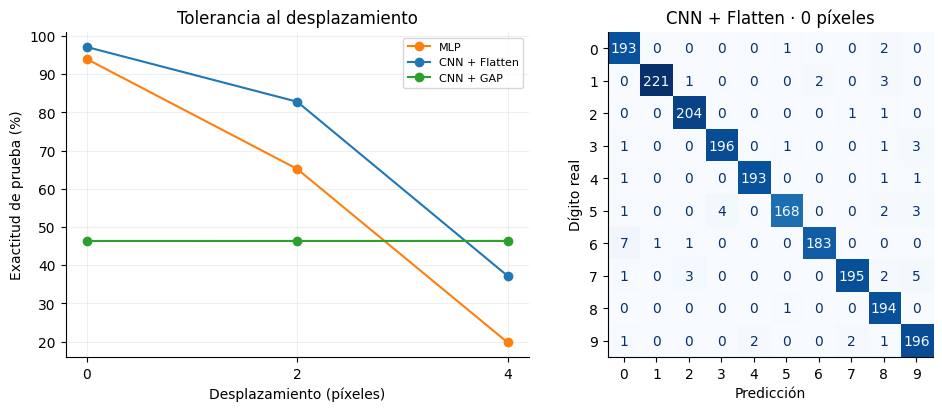

In [25]:
def desplazar(imagenes, dy, dx):
    if max(abs(dy), abs(dx)) > MARGEN:
        raise ValueError("Usa un desplazamiento dentro del margen de la imagen.")
    alto, ancho = imagenes.shape[1:3]
    resultado = np.zeros_like(imagenes)
    origen_y = slice(max(-dy, 0), alto - max(dy, 0))
    origen_x = slice(max(-dx, 0), ancho - max(dx, 0))
    destino_y = slice(max(dy, 0), alto - max(-dy, 0))
    destino_x = slice(max(dx, 0), ancho - max(-dx, 0))
    resultado[:, destino_y, destino_x, :] = imagenes[:, origen_y, origen_x, :]
    return resultado

def predecir(modelo, imagenes):
    return modelo.predict(lotes(imagenes), verbose=0).argmax(axis=1)

modelos = {"MLP": modelo_mlp, "CNN + Flatten": modelo_cnn, "CNN + GAP": modelo_gap}
distancias = (0, 2, 4)
pred_originales = {nombre: predecir(modelo, X_prueba) for nombre, modelo in modelos.items()}
exactitudes = {
    nombre: [100 * np.mean(pred == y_prueba)]
    for nombre, pred in pred_originales.items()
}
pred_derecha = {}
for distancia in distancias[1:]:
    resultados_direccion = {nombre: [] for nombre in modelos}
    direcciones = ((0, distancia), (0, -distancia), (distancia, 0), (-distancia, 0))
    for dy, dx in direcciones:
        imagenes = desplazar(X_prueba, dy, dx)
        for nombre, modelo in modelos.items():
            pred = predecir(modelo, imagenes)
            resultados_direccion[nombre].append(100 * np.mean(pred == y_prueba))
            if dy == 0 and dx == MARGEN:
                pred_derecha[nombre] = pred
    for nombre, valores in resultados_direccion.items():
        exactitudes[nombre].append(float(np.mean(valores)))

tabla = pd.DataFrame.from_dict(exactitudes, orient="index",
                               columns=[f"{d} px (%)" for d in distancias])
tabla["Caída a 4 px (pp)"] = tabla["0 px (%)"] - tabla["4 px (%)"]
tabla.index.name = "Modelo"
display(tabla.round(2))

fig, ejes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for nombre, color in zip(modelos, ("C1", "C0", "C2")):
    ejes[0].plot(distancias, exactitudes[nombre], marker="o", label=nombre, color=color)
ejes[0].set(title="Tolerancia al desplazamiento", xlabel="Desplazamiento (píxeles)",
            ylabel="Exactitud de prueba (%)", xticks=distancias)
ejes[0].legend(fontsize=8)
ejes[0].grid(alpha=0.2)
ConfusionMatrixDisplay.from_predictions(
    y_prueba, pred_originales["CNN + Flatten"], labels=list(range(10)),
    ax=ejes[1], cmap="Blues", colorbar=False,
)
ejes[1].set(title="CNN + Flatten · 0 píxeles", xlabel="Predicción", ylabel="Dígito real")
plt.show()

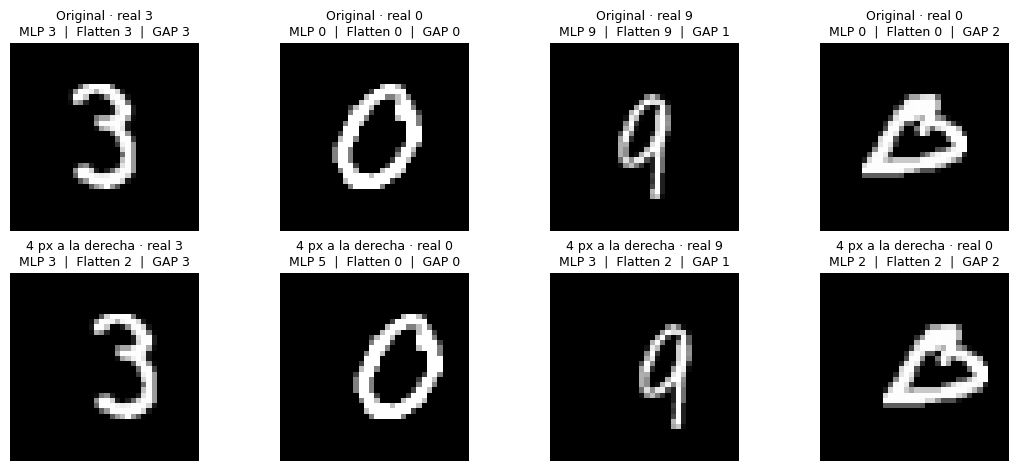

In [26]:
# Busca casos en que algún modelo acertaba y deja de acertar al mover el dígito.
cambia = np.zeros(len(y_prueba), dtype=bool)
for nombre in modelos:
    cambia |= (pred_originales[nombre] == y_prueba) & (pred_derecha[nombre] != y_prueba)
indices = np.flatnonzero(cambia)[:4]
if len(indices) == 0:
    indices = np.arange(4)
    print("Todos los aciertos se conservaron en este desplazamiento. Se muestran cuatro ejemplos.")

fig, ejes = plt.subplots(2, len(indices), figsize=(2.7 * len(indices), 4.6),
                         squeeze=False, layout="constrained")
for columna, i in enumerate(indices):
    par = (X_prueba[i, ..., 0], desplazar(X_prueba[i:i + 1], 0, MARGEN)[0, ..., 0])
    for fila, (etiqueta, pred) in enumerate([
        ("Original", pred_originales), ("4 px a la derecha", pred_derecha),
    ]):
        ax = ejes[fila, columna]
        ax.imshow(par[fila], cmap="gray", vmin=0, vmax=1)
        ax.set_title(
            f"{etiqueta} · real {y_prueba[i]}\n"
            f"MLP {pred['MLP'][i]}  |  Flatten {pred['CNN + Flatten'][i]}  |  GAP {pred['CNN + GAP'][i]}",
            fontsize=9,
        )
        ax.axis("off")
plt.show()

## 7. Actividad para experimentar

En la ejecución guardada, la CNN con GAP obtuvo 46.3 % de exactitud tanto en las imágenes originales como en las desplazadas. Interpreta la pendiente de la curva junto con su nivel de exactitud. Con este extractor pequeño y tres épocas, promediar cada canal dio un vector compacto, pero el modelo distinguió pocos dígitos.

1. **Padding y stride.** Predice a mano la forma antes de Flatten con `padding="valid"`. Repite con `stride=2` en la primera convolución y padding same. Compara con la tabla.
2. **Pooling.** Max y average pooling conservan la misma forma. ¿Qué diferencias ves en validación? ¿Qué ocurre con la capa densa al quitar pooling?
3. **Flatten y GAP.** ¿Cuántos pesos ahorra GAP en la capa densa? Compara tanto la exactitud a 0 píxeles como su caída a 4. Un modelo puede sufrir una caída menor y aun así tener menor exactitud final.
4. **Traslación.** Elige un dígito que algún modelo dejó de reconocer. ¿En qué dirección lo desplazamos? ¿Cuál fue el error? ¿Los tres modelos cambiaron su predicción?
5. **Reproducibilidad.** Cambia la semilla de inicialización dentro de `entrenar` y vuelve a comparar dos configuraciones usando la misma partición. Las gráficas de esta práctica describen una ejecución con un presupuesto corto de entrenamiento.

### Declaración de uso de IA generativa

Este notebook fue elaborado con apoyo de ChatGPT 6.1 Sol Medium para estructurar el contenido a partir de las diapositivas de la sesión y redactar el texto explicativo. El diseño pedagógico, la selección de temas y la revisión final son responsabilidad del titular del curso.